This code is just a preliminary look at some of the clarity data.

You will need to download the ~2GB dataset from: https://data.cityofchicago.org/Health-Human-Services/Open-Air-Chicago-Individual-Measurements/xfya-dxtq/about_data
In the top right, click on Export and download the file as a .csv (note: This export process does take some time, so be patient).


Notebook authorship
Author: Noah Ring
Year: 2026
Program: EarthRISE Developers Academy

In [1]:
#Some of these packages are unused.
import pandas as pd
import datetime as dt
from datetime import datetime
from dateutil.relativedelta import relativedelta
import xarray as xr
import matplotlib.pyplot as plt
from mpl_toolkits.basemap import Basemap
import seaborn as sb
import geopandas as gpd
import geodatasets as geodat
import numpy as np
import seaborn as sns
from matplotlib_scalebar.scalebar import ScaleBar
import matplotlib.colors as mcolors


colors = ['#dadaeb','#bcbddc',
          '#9e9ac8',
          '#807dba','#6a51a3','#54278f','#3f007d']

cmap = mcolors.LinearSegmentedColormap.from_list('purples_custom', colors)

#Change the matplotlib dpi to increase or decrease output size in vscode
plt.rcParams['figure.dpi'] = 200 

#Define the path where your data is stored.
data_folder = "~/Documents/01_Research/larc-chicago-haq/datasets/"

#Load chicago community population dataset. We will pull shapefiles from this.
#This just has population from 2010, but honestly it would potentially be interesting to do no2 levels per 100k or something 
#i.e. alludes to exposure
chicago = gpd.read_file(geodat.get_path("geoda.chicago_commpop"))

#look at the first five rows
chicago.head()


/home/nlring/.conda/envs/chi-haq/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


,community,NID,POP2010,POP2000,POPCH,POPPERCH,popplus,popneg,geometry
0,DOUGLAS,35,18238,26470,-8232,-31.099358,0,1,"MULTIPOLYGON (((-87.60914 41.84469, -87.60915 ..."
1,OAKLAND,36,5918,6110,-192,-3.142390,0,1,"MULTIPOLYGON (((-87.59215 41.81693, -87.59231 ..."
2,FULLER PARK,37,2876,3420,-544,-15.906433,0,1,"MULTIPOLYGON (((-87.6288 41.80189, -87.62879 4..."
3,GRAND BOULEVARD,38,21929,28006,-6077,-21.698922,0,1,"MULTIPOLYGON (((-87.60671 41.81681, -87.6067 4..."
4,KENWOOD,39,17841,18363,-522,-2.842673,0,1,"MULTIPOLYGON (((-87.59215 41.81693, -87.59215 ..."


In [2]:

#Define filename for dataset here.
file_dir = data_folder + "Open_Air_Chicago_Individual_Measurements_20260615.csv"

#Read in the full dataset for clarity sensors
cook_full = pd.read_csv(file_dir)


In [24]:

#Subset the data for our variables of interest
cook_clarity = cook_full[['sensor_name', 'latitude', 'longitude', 'time',
                            'no2ConcIndividual.value', 'no2ConcIndividual.raw', 
                            'pm2_5ConcMassIndividual.raw', 'pm2_5ConcMassIndividual.value', 
                            'pm2_5ConcNumIndividual.value', 'pm2_5ConcNumIndividual.raw']]

cook_clarity["time"] = pd.to_datetime(cook_clarity["time"], format="%m/%d/%Y %I:%M:%S %p")
cook_clarity["month"] = cook_clarity["time"].dt.month
cook_clarity["year"] = cook_clarity["time"].dt.year
cook_clarity["month_year_str"] = cook_clarity['month'].astype(str) + "-" + cook_clarity['year'].astype(str)
cook_clarity["month_year"] = pd.to_datetime(cook_clarity["month_year_str"], format="%m-%Y")
# datetime.strptime(cook_clarity["time"], "%m/%d/%Y %I:%M:%S %p")


#Convert to geopandas dataframe
cook_clarity["geometry"] = gpd.points_from_xy(
    x = cook_clarity["longitude"],
    y = cook_clarity["latitude"]
)

#Set coordinate reference system to match crs of data we downloaded earlier
cook_clarity = gpd.GeoDataFrame(cook_clarity).set_crs(chicago.crs)

#Print type
print(type(cook_clarity))

#This line just gets the sensor count. 
print(np.unique(cook_clarity['sensor_name']).shape[0])
print(np.unique(cook_clarity['latitude']).shape[0])

#Print the first five lines
print(cook_clarity.head(5))



<class 'geopandas.geodataframe.GeoDataFrame'>
286
280
                sensor_name   latitude  longitude                time  \
0            Logan Square 3  41.921811 -87.690637 2026-01-18 13:14:59   
1             Irving Park 4  41.941523 -87.735605 2026-01-18 12:24:16   
2               West Town 4  41.894832 -87.672764 2026-06-10 23:05:39   
3               Englewood 1  41.789686 -87.652596 2026-03-27 09:36:07   
4  Greater Grand Crossing 6  41.751465 -87.636296 2026-04-28 07:23:59   

   no2ConcIndividual.value  no2ConcIndividual.raw  \
0                      NaN                    NaN   
1                      NaN                    NaN   
2                    17.55                  35.76   
3                     9.21                  12.28   
4                     8.69                   5.73   

   pm2_5ConcMassIndividual.raw  pm2_5ConcMassIndividual.value  \
0                         2.58                           6.48   
1                         2.58                           3

In [28]:
#get % of missing per sensor
#note that this is just for the "no2ConcIndividual.value" variable in the dataframe
cook_clarity_na_count = (
    cook_clarity.groupby(["sensor_name", "longitude", "latitude","month", "month_year"])["no2ConcIndividual.value"]
    .apply(lambda x: 100 * x.isna().mean())
    .reset_index()
)


cook_clarity_na_count = cook_clarity_na_count.merge(
    cook_clarity.groupby(["sensor_name", "longitude", "latitude","month","month_year"])
    .size()
    .reset_index(name="num_vals"),
    on=["sensor_name", "longitude", "latitude", "month","month_year"],
    how="left",
)


cook_clarity_na_count.rename(columns={"no2ConcIndividual.value": "percent_missing_no2"}, inplace=True)

# cook_clarity_na_count.to_csv("~/Documents/01_Research/larc-chicago-haq/datasets/missing-output.csv")

#Print first five rows
print(cook_clarity_na_count.head())

#Convert above dataframe to geopandas dataframe
#important to assign longitude and latitude for plotting
#This will need to be done for other statistics we calculate per station as well.
cook_clarity_na_count["geometry"] = gpd.points_from_xy(
    x=cook_clarity_na_count["longitude"],
    y=cook_clarity_na_count["latitude"]
)

#Set coordinate reference system to match crs of data we downloaded earlier
cook_clarity_na_count = gpd.GeoDataFrame(cook_clarity_na_count).set_crs(chicago.crs)


     sensor_name  longitude   latitude  month month_year  percent_missing_no2  \
0  Albany Park 1 -87.725577  41.975287      1 2026-01-01            70.611133   
1  Albany Park 1 -87.725577  41.975287      2 2026-02-01            50.625270   
2  Albany Park 1 -87.725577  41.975287      3 2026-03-01            15.066354   
3  Albany Park 1 -87.725577  41.975287      4 2026-04-01             0.403551   
4  Albany Park 1 -87.725577  41.975287      5 2026-05-01             0.000000   

   num_vals  
0      2569  
1      2319  
2      2562  
3      2478  
4      4691  


In [27]:
cook_clarity_na_count

,sensor_name,longitude,latitude,month,month_year,percent_missing_no2,num_vals
0,Albany Park 1,-87.725577,41.975287,1,2026-01-01,70.611133,2569
1,Albany Park 1,-87.725577,41.975287,2,2026-02-01,50.625270,2319
2,Albany Park 1,-87.725577,41.975287,3,2026-03-01,15.066354,2562
3,Albany Park 1,-87.725577,41.975287,4,2026-04-01,0.403551,2478
4,Albany Park 1,-87.725577,41.975287,5,2026-05-01,0.000000,4691
...,...,...,...,...,...,...,...
2810,Woodlawn 2,-87.585796,41.776770,6,2026-06-01,0.000000,3542
2811,Woodlawn 2,-87.585796,41.776770,9,2025-09-01,0.000000,2470
2812,Woodlawn 2,-87.585796,41.776770,10,2025-10-01,0.000000,2551
2813,Woodlawn 2,-87.585796,41.776770,11,2025-11-01,12.992286,2463


/tmp/ipykernel_57489/2925208567.py:50: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


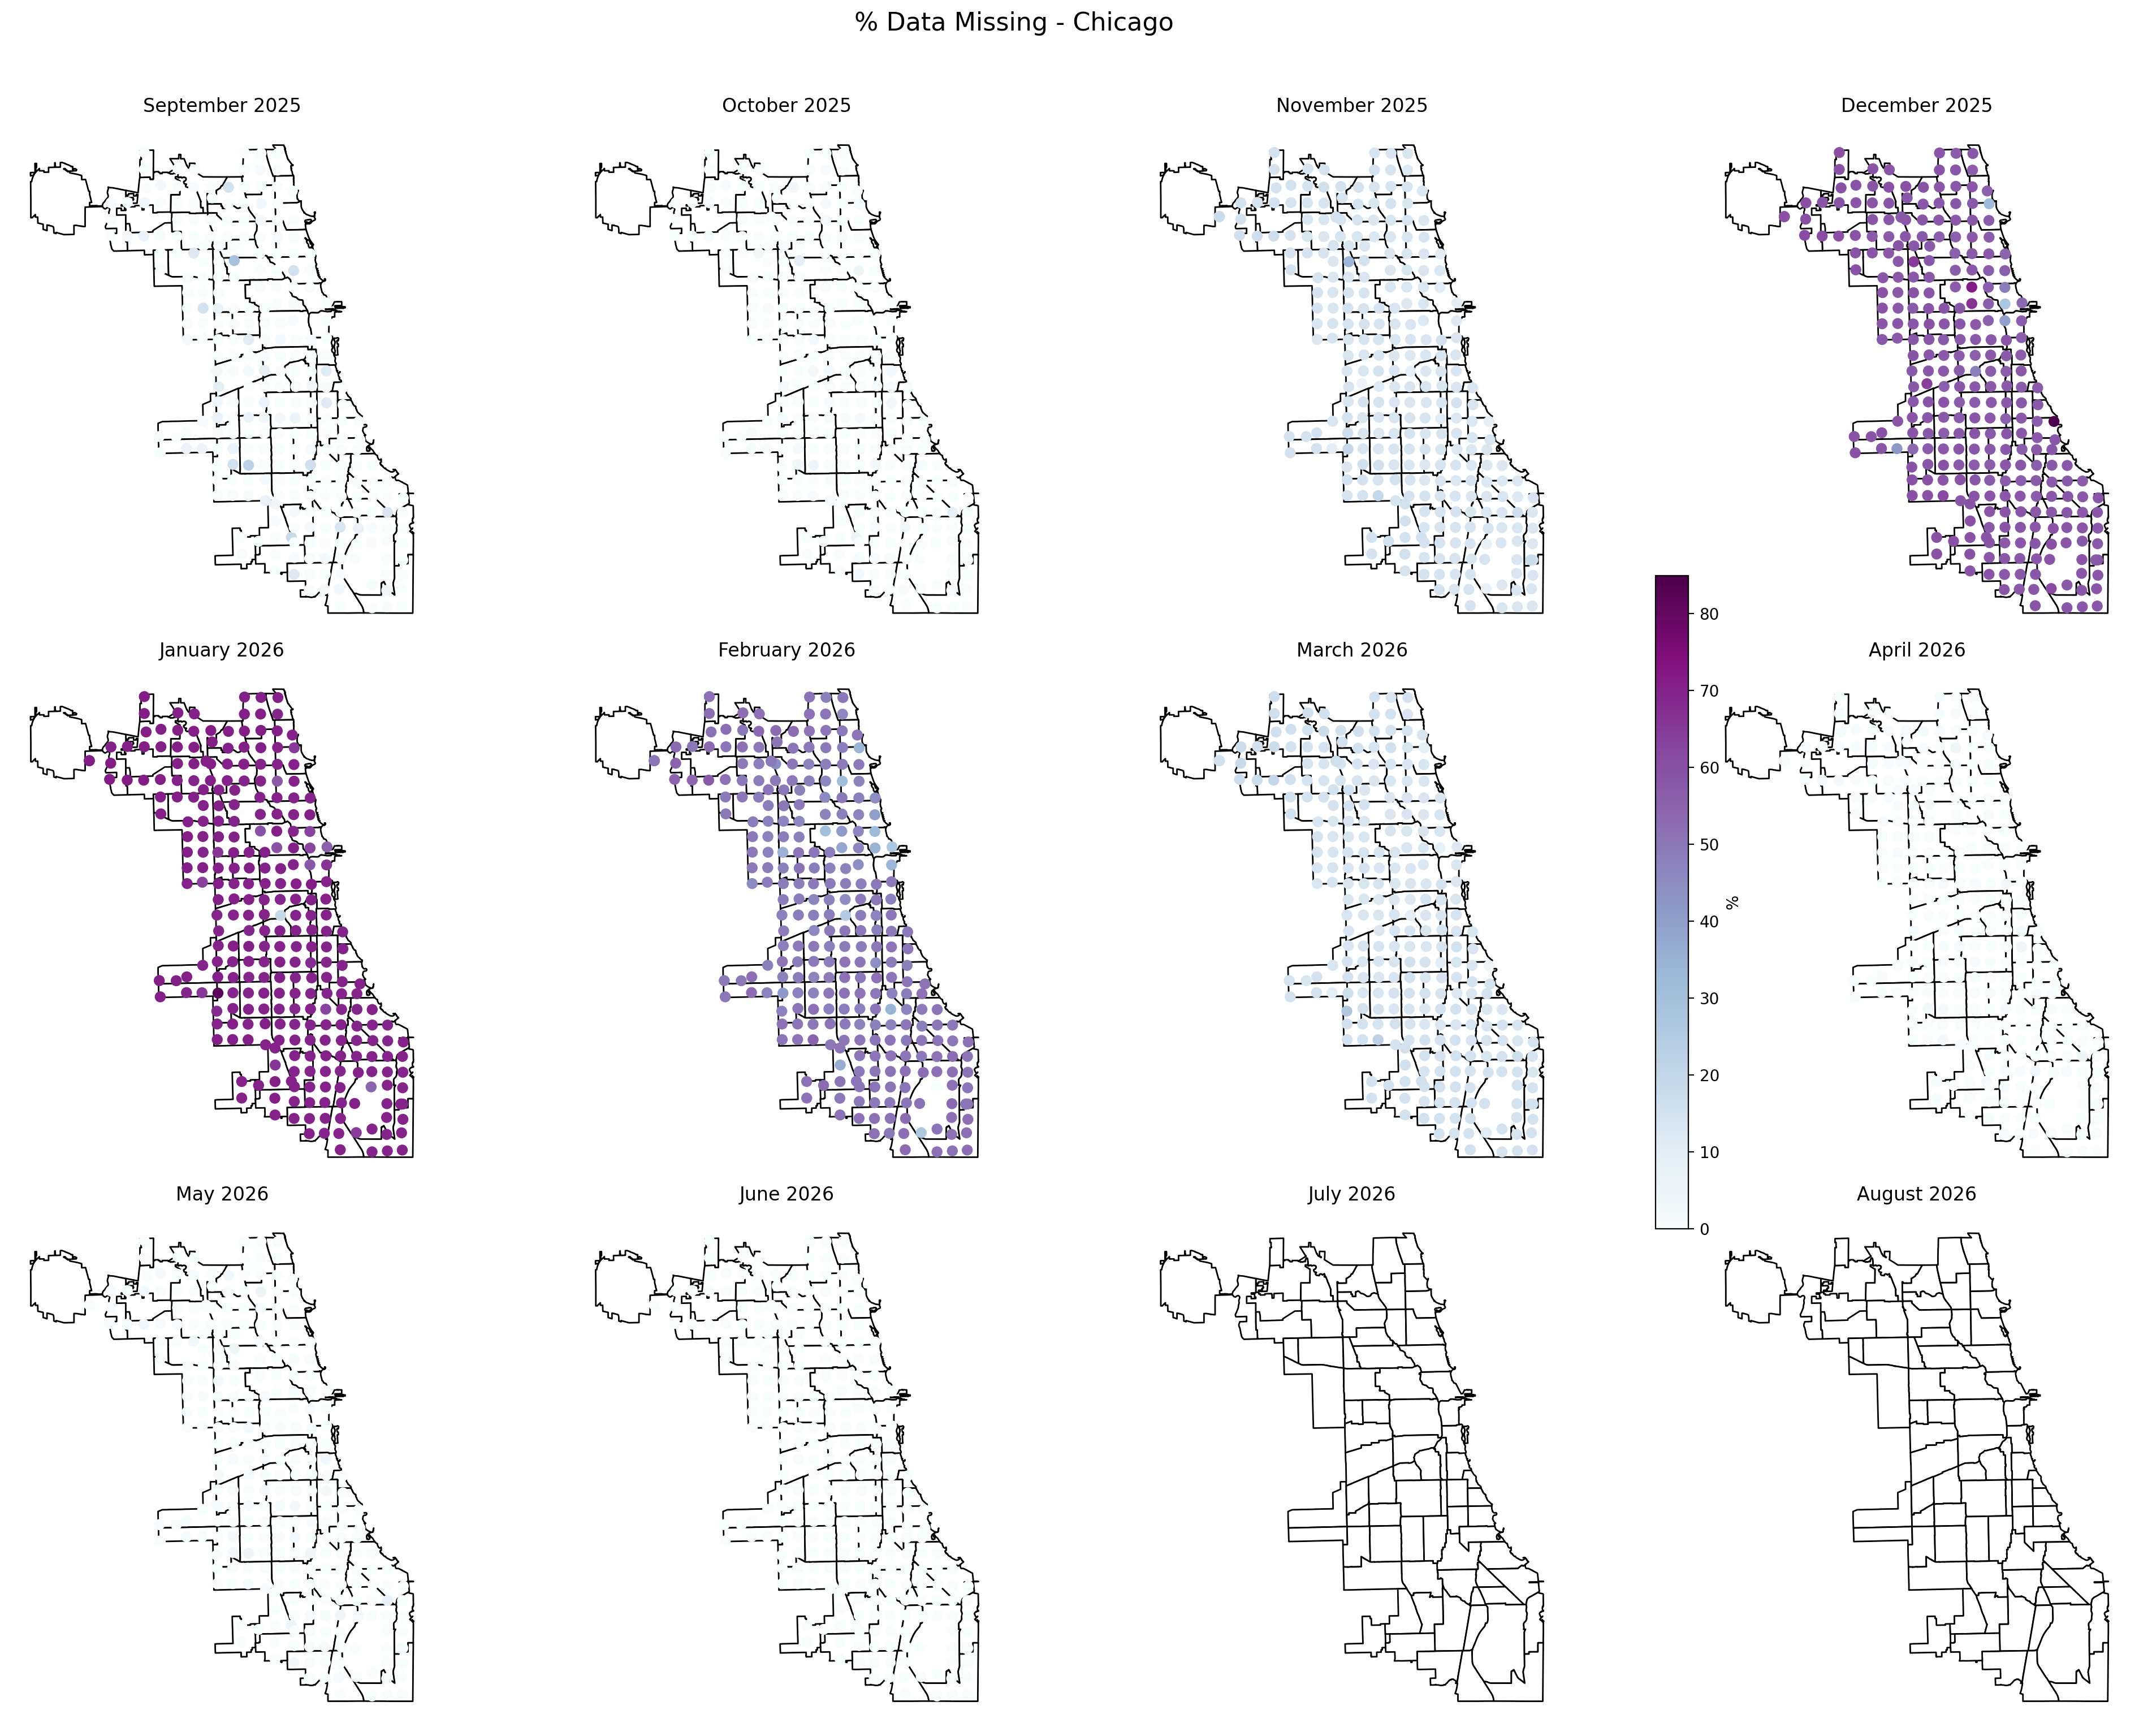

In [ ]:
chi_result_na = cook_clarity_na_count

months = chi_result_na['month_year'].unique()
months = months[months.argsort()]

start_date = chi_result_na['month_year'].min()
end_date = chi_result_na['month_year'].max()

delta = relativedelta(months=1)

fig, axes = plt.subplots(
    nrows=3, ncols=4,
    figsize=(20, 15)
)

for ax, month in zip(axes.flatten(), range(1,13)):
    # ax = axes[i]
    
    # Base Chicago boundary
    chicago.plot(color='white', edgecolor='black', ax=ax)
    
    # Filter to month
    monthly_data = chi_result_na[chi_result_na['month_year'] == start_date]
    
    if not monthly_data.empty:
        monthly_data.plot(ax=ax, column='percent_missing_no2', cmap='Bu',
                          vmin=chi_result_na['percent_missing_no2'].min(),
                          vmax=chi_result_na['percent_missing_no2'].max())
    
    # ax.set_title(calendar.month_name[month])
    # ax.axis('off')
  
    title_date = dt.date(start_date.year, start_date.month, start_date.day).strftime('%B %Y')
    ax.set_title(title_date, fontsize=12)
    ax.axis('off')
    start_date += delta

# Shared colorbar
sm = plt.cm.ScalarMappable(
    cmap='BuPu',
    norm=plt.Normalize(
        vmin=chi_result_na['percent_missing_no2'].min(),
        vmax=chi_result_na['percent_missing_no2'].max()
    )
)
sm._A = []
fig.colorbar(sm, ax=axes, shrink=0.5, label='%')

plt.suptitle('% Data Missing - Chicago', fontsize=16, y=1.02)
plt.tight_layout()
# plt.savefig("month_percent_missing-individual.png")
plt.show()

In [22]:

#Print first five rows
print(cook_clarity_na_count.head())

#Convert above dataframe to geopandas dataframe
#important to assign longitude and latitude for plotting
#This will need to be done for other statistics we calculate per station as well.
cook_clarity_na_count["geometry"] = gpd.points_from_xy(
    x=cook_clarity_na_count["longitude"],
    y=cook_clarity_na_count["latitude"]
)

#Set coordinate reference system to match crs of data we downloaded earlier
cook_clarity_na_count = gpd.GeoDataFrame(cook_clarity_na_count).set_crs(chicago.crs)


     sensor_name  longitude   latitude  month  percent_missing_no2  num_vals
0  Albany Park 1 -87.725577  41.975287      1            70.611133      2569
1  Albany Park 1 -87.725577  41.975287      2            50.625270      2319
2  Albany Park 1 -87.725577  41.975287      3            15.066354      2562
3  Albany Park 1 -87.725577  41.975287      4             0.403551      2478
4  Albany Park 1 -87.725577  41.975287      5             0.000000      4691


        sensor_name  longitude   latitude  percent_missing_no2  num_vals  \
0     Albany Park 1 -87.725577  41.975287            18.501486     28268   
1     Albany Park 2 -87.708572  41.962378            17.761189     28399   
2     Albany Park 3 -87.726382  41.962488            18.286135     28497   
3  Archer Heights 1 -87.736277  41.815592            18.253413     28570   
4  Archer Heights 2 -87.719974  41.815328            18.363112     28432   

                     geometry  
0  POINT (-87.72558 41.97529)  
1  POINT (-87.70857 41.96238)  
2  POINT (-87.72638 41.96249)  
3  POINT (-87.73628 41.81559)  
4  POINT (-87.71997 41.81533)  
<class 'geopandas.geodataframe.GeoDataFrame'>
EPSG:4326
EPSG:4326


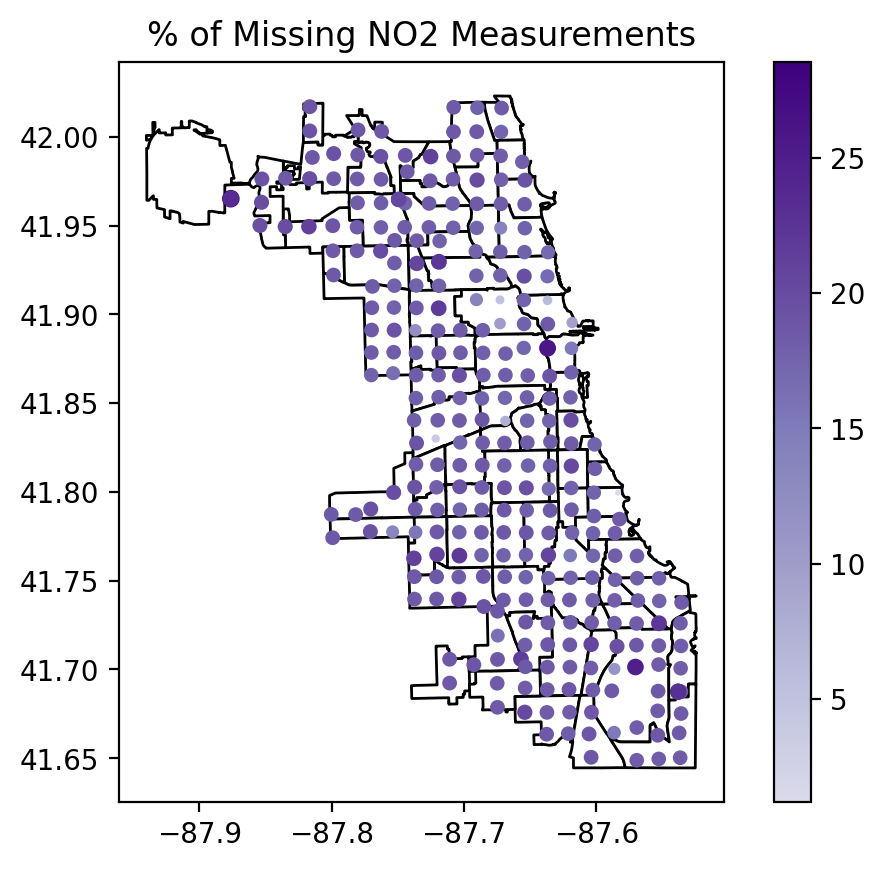

In [8]:

#we can peak at the first five lines of the geodataframe
print(cook_clarity_na_count.head())

#lets print to make sure its in the right format
print(type(cook_clarity_na_count))

#Print the CRS of both geodataframes to confirm
print(chicago.crs)
print(cook_clarity_na_count.crs)

#Now we construct a first map, where the color corresponds to the number of missing values per sensor.
ax = chicago.plot(color='white', edgecolor='black')

cook_clarity_na_count.plot(
    ax=ax,
    # markersize=0.05*cook_clarity_na_count['num_missing_no2']**2, 
    markersize=cook_clarity_na_count['percent_missing_no2'],
    figsize=(10,10),
    column='percent_missing_no2',
    cmap=cmap, 
    legend=True)

# ax.add_artist(ScaleBar(1))
plt.title("% of Missing NO2 Measurements")
plt.savefig("perc_missing_stations.png")

In [5]:
#now we combine the clarity point data and datasets

chi_joined = gpd.sjoin(cook_clarity, 
                        chicago[["community", "NID", "geometry"]],
                        how="left",
                        predicate="within")

# calculate the number of points per community
counts = (
    chi_joined.groupby(["community", "NID"])
    .size()
    .reset_index(name="point_count")
)

#calculate the average NO2 value per community
chi_summary = (
    chi_joined.groupby(["community", "NID"])
    .agg(
        avg_value=("no2ConcIndividual.value", "mean")
    )
    .reset_index()
)

#left join the datasets to the chicago community shapefile data
chi_result = chicago.merge(chi_summary, on="NID", how="left")
chi_result = chi_result.merge(counts, on="NID", how="left")

chi_result

,community_x,NID,POP2010,POP2000,POPCH,POPPERCH,popplus,popneg,geometry,community_y,avg_value,community,point_count
0,DOUGLAS,35,18238,26470,-8232,-31.099358,0,1,"MULTIPOLYGON (((-87.60914 41.84469, -87.60915 ...",DOUGLAS,13.556242,DOUGLAS,56868.0
1,OAKLAND,36,5918,6110,-192,-3.142390,0,1,"MULTIPOLYGON (((-87.59215 41.81693, -87.59231 ...",OAKLAND,13.891230,OAKLAND,28153.0
2,FULLER PARK,37,2876,3420,-544,-15.906433,0,1,"MULTIPOLYGON (((-87.6288 41.80189, -87.62879 4...",FULLER PARK,15.673210,FULLER PARK,28694.0
3,GRAND BOULEVARD,38,21929,28006,-6077,-21.698922,0,1,"MULTIPOLYGON (((-87.60671 41.81681, -87.6067 4...",GRAND BOULEVARD,15.308386,GRAND BOULEVARD,57006.0
4,KENWOOD,39,17841,18363,-522,-2.842673,0,1,"MULTIPOLYGON (((-87.59215 41.81693, -87.59215 ...",KENWOOD,12.485430,KENWOOD,28563.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
72,MOUNT GREENWOOD,74,19093,18820,273,1.450584,1,0,"MULTIPOLYGON (((-87.69646 41.70714, -87.69644 ...",MOUNT GREENWOOD,14.062320,MOUNT GREENWOOD,57229.0
73,MORGAN PARK,75,22544,25226,-2682,-10.631888,0,1,"MULTIPOLYGON (((-87.64215 41.68508, -87.64249 ...",MORGAN PARK,15.392037,MORGAN PARK,85541.0
74,OHARE,76,12756,11956,800,6.691201,1,0,"MULTIPOLYGON (((-87.83658 41.9864, -87.83658 4...",OHARE,13.979880,OHARE,85226.0
75,EDGEWATER,77,56521,62198,-5677,-9.127303,0,1,"MULTIPOLYGON (((-87.65456 41.99817, -87.65456 ...",EDGEWATER,13.915433,EDGEWATER,56407.0


In [ ]:
# chi_result.to_file("~/Documents/01_Research/larc-chicago-haq/chi-community-mean-test.json", driver="GeoJSON")

Text(0.5, 1.0, 'Average NO2 Concentration ')

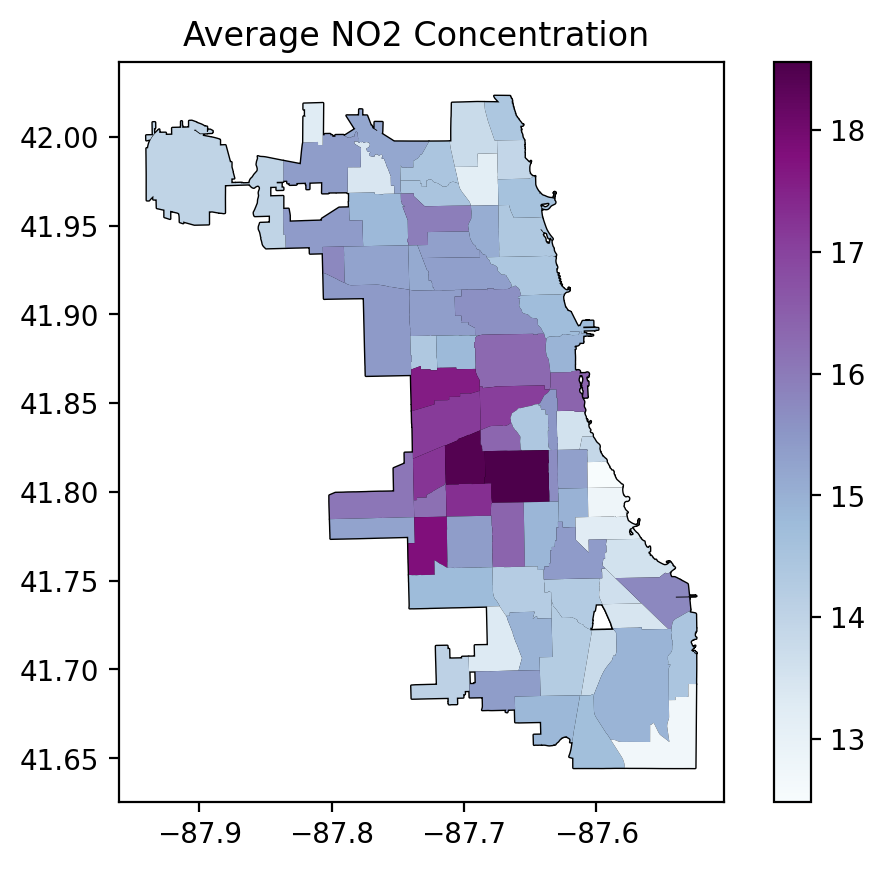

In [ ]:
#plot average no2 value
base = chicago.plot(color='white', edgecolor='black')

chi_result.plot(
    ax=base,
    figsize=(10,10),
    column='avg_value',
    cmap='viridis', 
    legend=True)

plt.title("Average NO2 Concentration ")

# plt.savefig("avg_no2.png")


Text(0.5, 1.0, 'Station Count per Chicago Neighborhood')

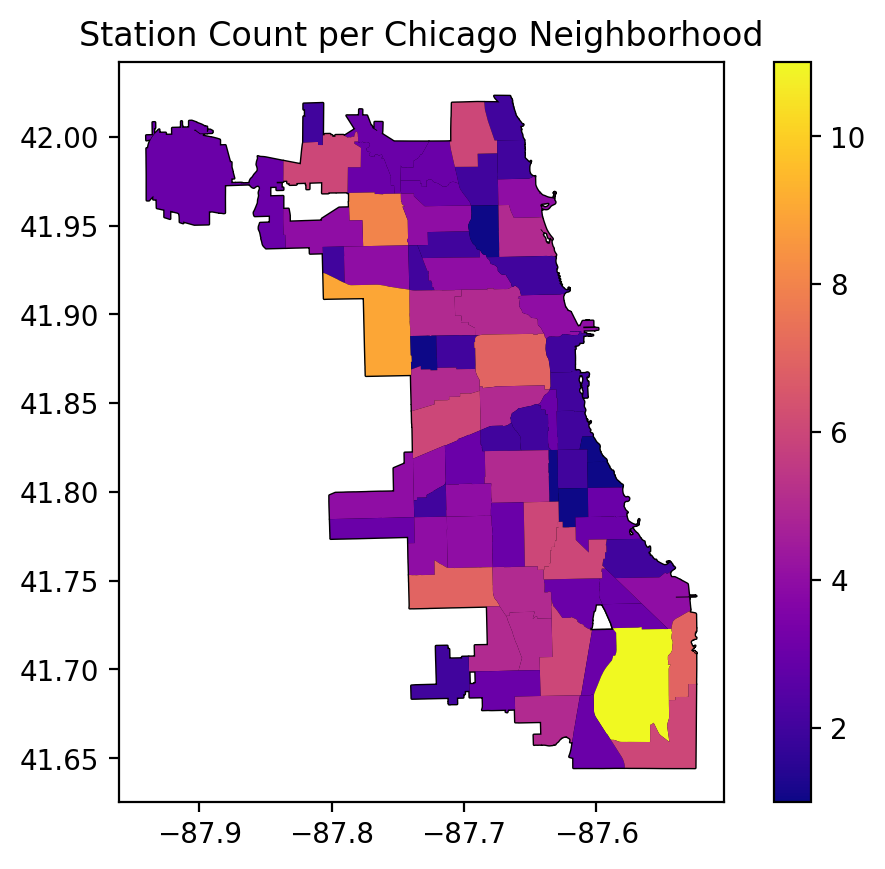

In [15]:
#plot number of stations per neighborhood
base = chicago.plot(color='white', edgecolor='black')

chi_result.plot(
    ax=base,
    figsize=(10,10),
    column='point_count',
    cmap='plasma', 
    legend=True)

plt.title("Station Count per Chicago Neighborhood")


In [36]:
#calculate monthly average and variance for no2 
chi_summary_monthly = (
    chi_joined.groupby(["community", "NID", "month", "year", "month_year"])
    .agg(
        avg_value=("no2ConcIndividual.value", "mean"),
        var_value=("no2ConcIndividual.value", "var")
    )
    .reset_index()
)

#left join the above with the chicago shapefile data
chi_result_monthly = chicago.merge(chi_summary_monthly, on="NID", how="left")

chi_result_monthly

,community_x,NID,POP2010,POP2000,POPCH,POPPERCH,popplus,popneg,geometry,community_y,month,year,month_year,avg_value,var_value
0,DOUGLAS,35,18238,26470,-8232,-31.099358,0,1,"MULTIPOLYGON (((-87.60914 41.84469, -87.60915 ...",DOUGLAS,1.0,2026.0,2026-01-01,15.818151,14.995488
1,DOUGLAS,35,18238,26470,-8232,-31.099358,0,1,"MULTIPOLYGON (((-87.60914 41.84469, -87.60915 ...",DOUGLAS,2.0,2026.0,2026-02-01,16.692866,28.319485
2,DOUGLAS,35,18238,26470,-8232,-31.099358,0,1,"MULTIPOLYGON (((-87.60914 41.84469, -87.60915 ...",DOUGLAS,3.0,2026.0,2026-03-01,14.191117,17.247361
3,DOUGLAS,35,18238,26470,-8232,-31.099358,0,1,"MULTIPOLYGON (((-87.60914 41.84469, -87.60915 ...",DOUGLAS,4.0,2026.0,2026-04-01,12.829054,18.447392
4,DOUGLAS,35,18238,26470,-8232,-31.099358,0,1,"MULTIPOLYGON (((-87.60914 41.84469, -87.60915 ...",DOUGLAS,5.0,2026.0,2026-05-01,12.394080,16.648685
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
756,EDISON PARK,9,11187,11259,-72,-0.639488,0,1,"MULTIPOLYGON (((-87.80676 42.00084, -87.80676 ...",EDISON PARK,6.0,2026.0,2026-06-01,12.606604,12.397746
757,EDISON PARK,9,11187,11259,-72,-0.639488,0,1,"MULTIPOLYGON (((-87.80676 42.00084, -87.80676 ...",EDISON PARK,9.0,2025.0,2025-09-01,13.545260,20.006117
758,EDISON PARK,9,11187,11259,-72,-0.639488,0,1,"MULTIPOLYGON (((-87.80676 42.00084, -87.80676 ...",EDISON PARK,10.0,2025.0,2025-10-01,12.511860,19.295174
759,EDISON PARK,9,11187,11259,-72,-0.639488,0,1,"MULTIPOLYGON (((-87.80676 42.00084, -87.80676 ...",EDISON PARK,11.0,2025.0,2025-11-01,13.358526,30.109976


/tmp/ipykernel_142334/3515301925.py:52: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


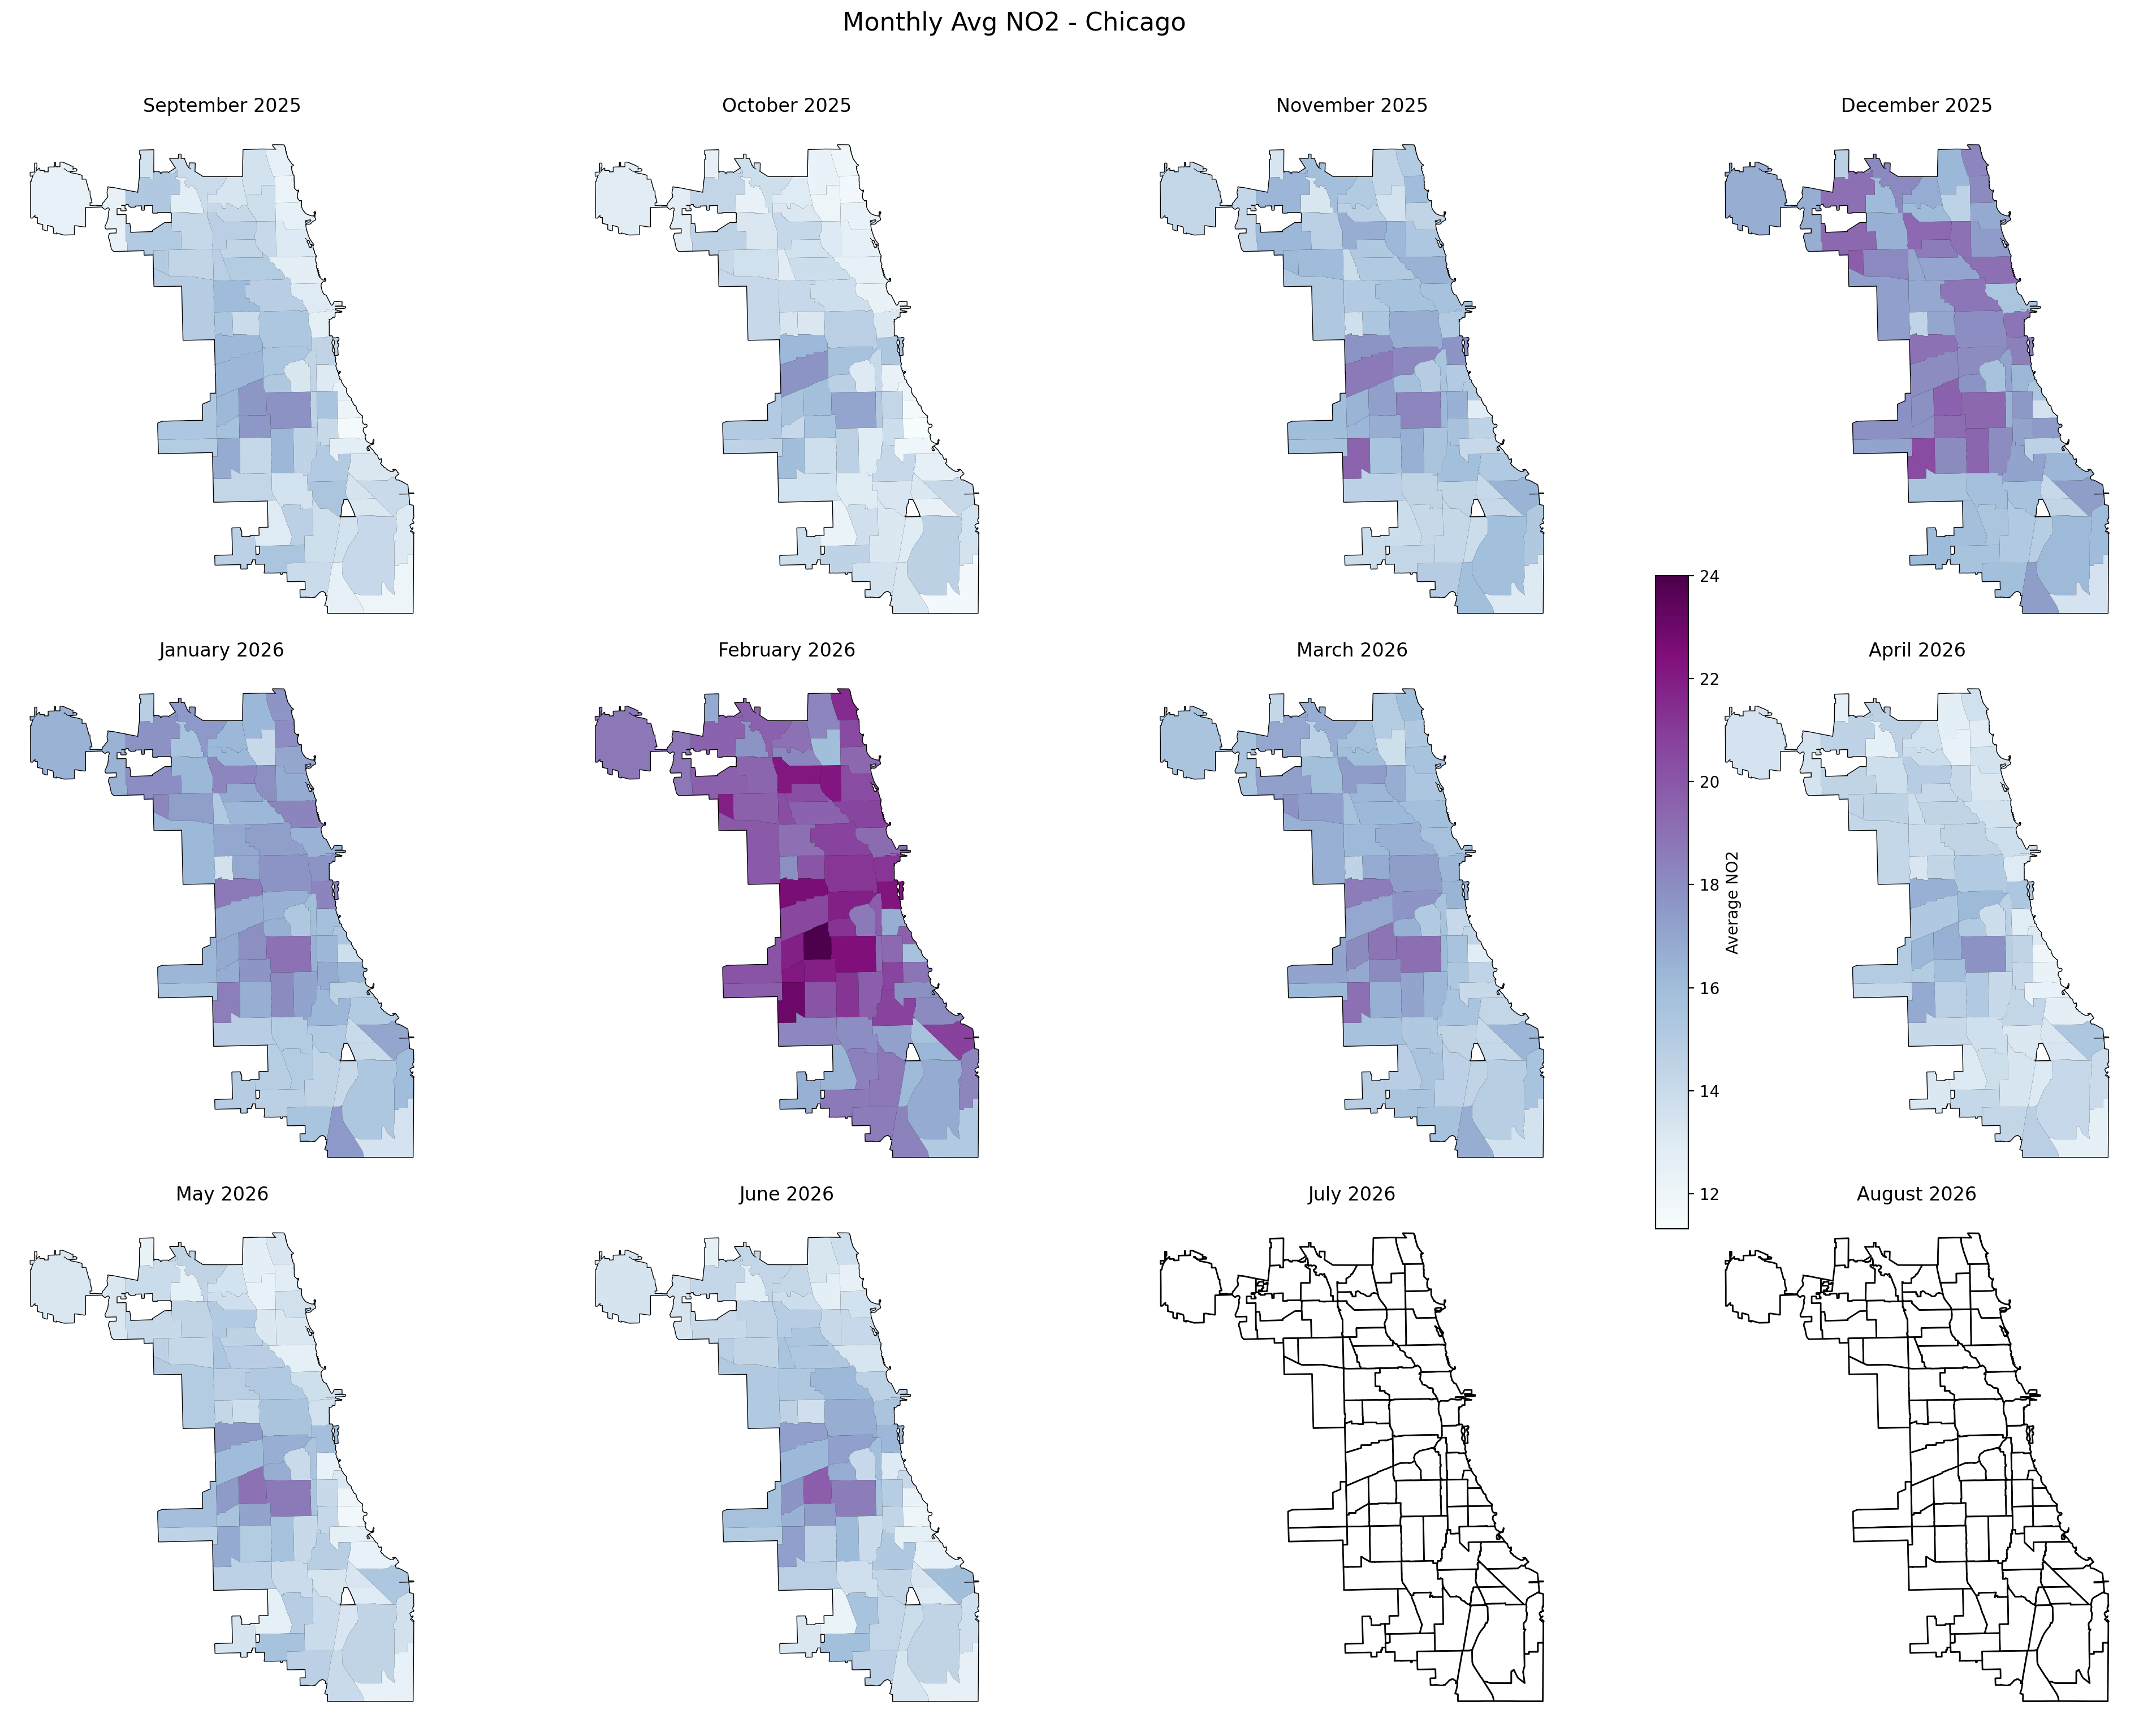

In [82]:
#NOTE: These facet plots feel very hacky. If there is a better way to do it, then by all means.

#Facet plot the monthly NO2 averages
months = chi_result_monthly['month_year'].unique()
months = months[months.argsort()]

start_date = chi_result_monthly['month_year'].min()
end_date = chi_result_monthly['month_year'].max()

delta = relativedelta(months=1)

fig, axes = plt.subplots(
    nrows=3, ncols=4,
    figsize=(20, 15)
)

for ax, month in zip(axes.flatten(), range(1,13)):
# while start_date <= end_date:
    # ax = axes[i]

    # Base Chicago boundary
    chicago.plot(color='white', edgecolor='black', ax=ax)
    
    # Filter to month
    monthly_data = chi_result_monthly[chi_result_monthly['month_year'] == start_date]
    
    if not monthly_data.empty:
        monthly_data.plot(ax=ax, column='avg_value', cmap='BuPu',
                          vmin=chi_result_monthly['avg_value'].min(),
                          vmax=chi_result_monthly['avg_value'].max())
    
    # ax.set_title(calendar.month_name[month])
    # ax.axis('off')
    title_date = dt.date(start_date.year, start_date.month, start_date.day).strftime('%B %Y')
    ax.set_title(title_date, fontsize=12)
    ax.axis('off')

    start_date += delta

# Shared colorbar
sm = plt.cm.ScalarMappable(
    cmap='BuPu',
    norm=plt.Normalize(
        vmin=chi_result_monthly['avg_value'].min(),
        vmax=chi_result_monthly['avg_value'].max()
    )
)
sm._A = []
fig.colorbar(sm, ax=axes, shrink=0.5, label='Average NO2')

plt.suptitle('Monthly Avg NO2 - Chicago', fontsize=16, y=1.02)
plt.tight_layout()
plt.savefig("month_avg_community.png")
plt.show()

/tmp/ipykernel_142334/3523700704.py:48: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


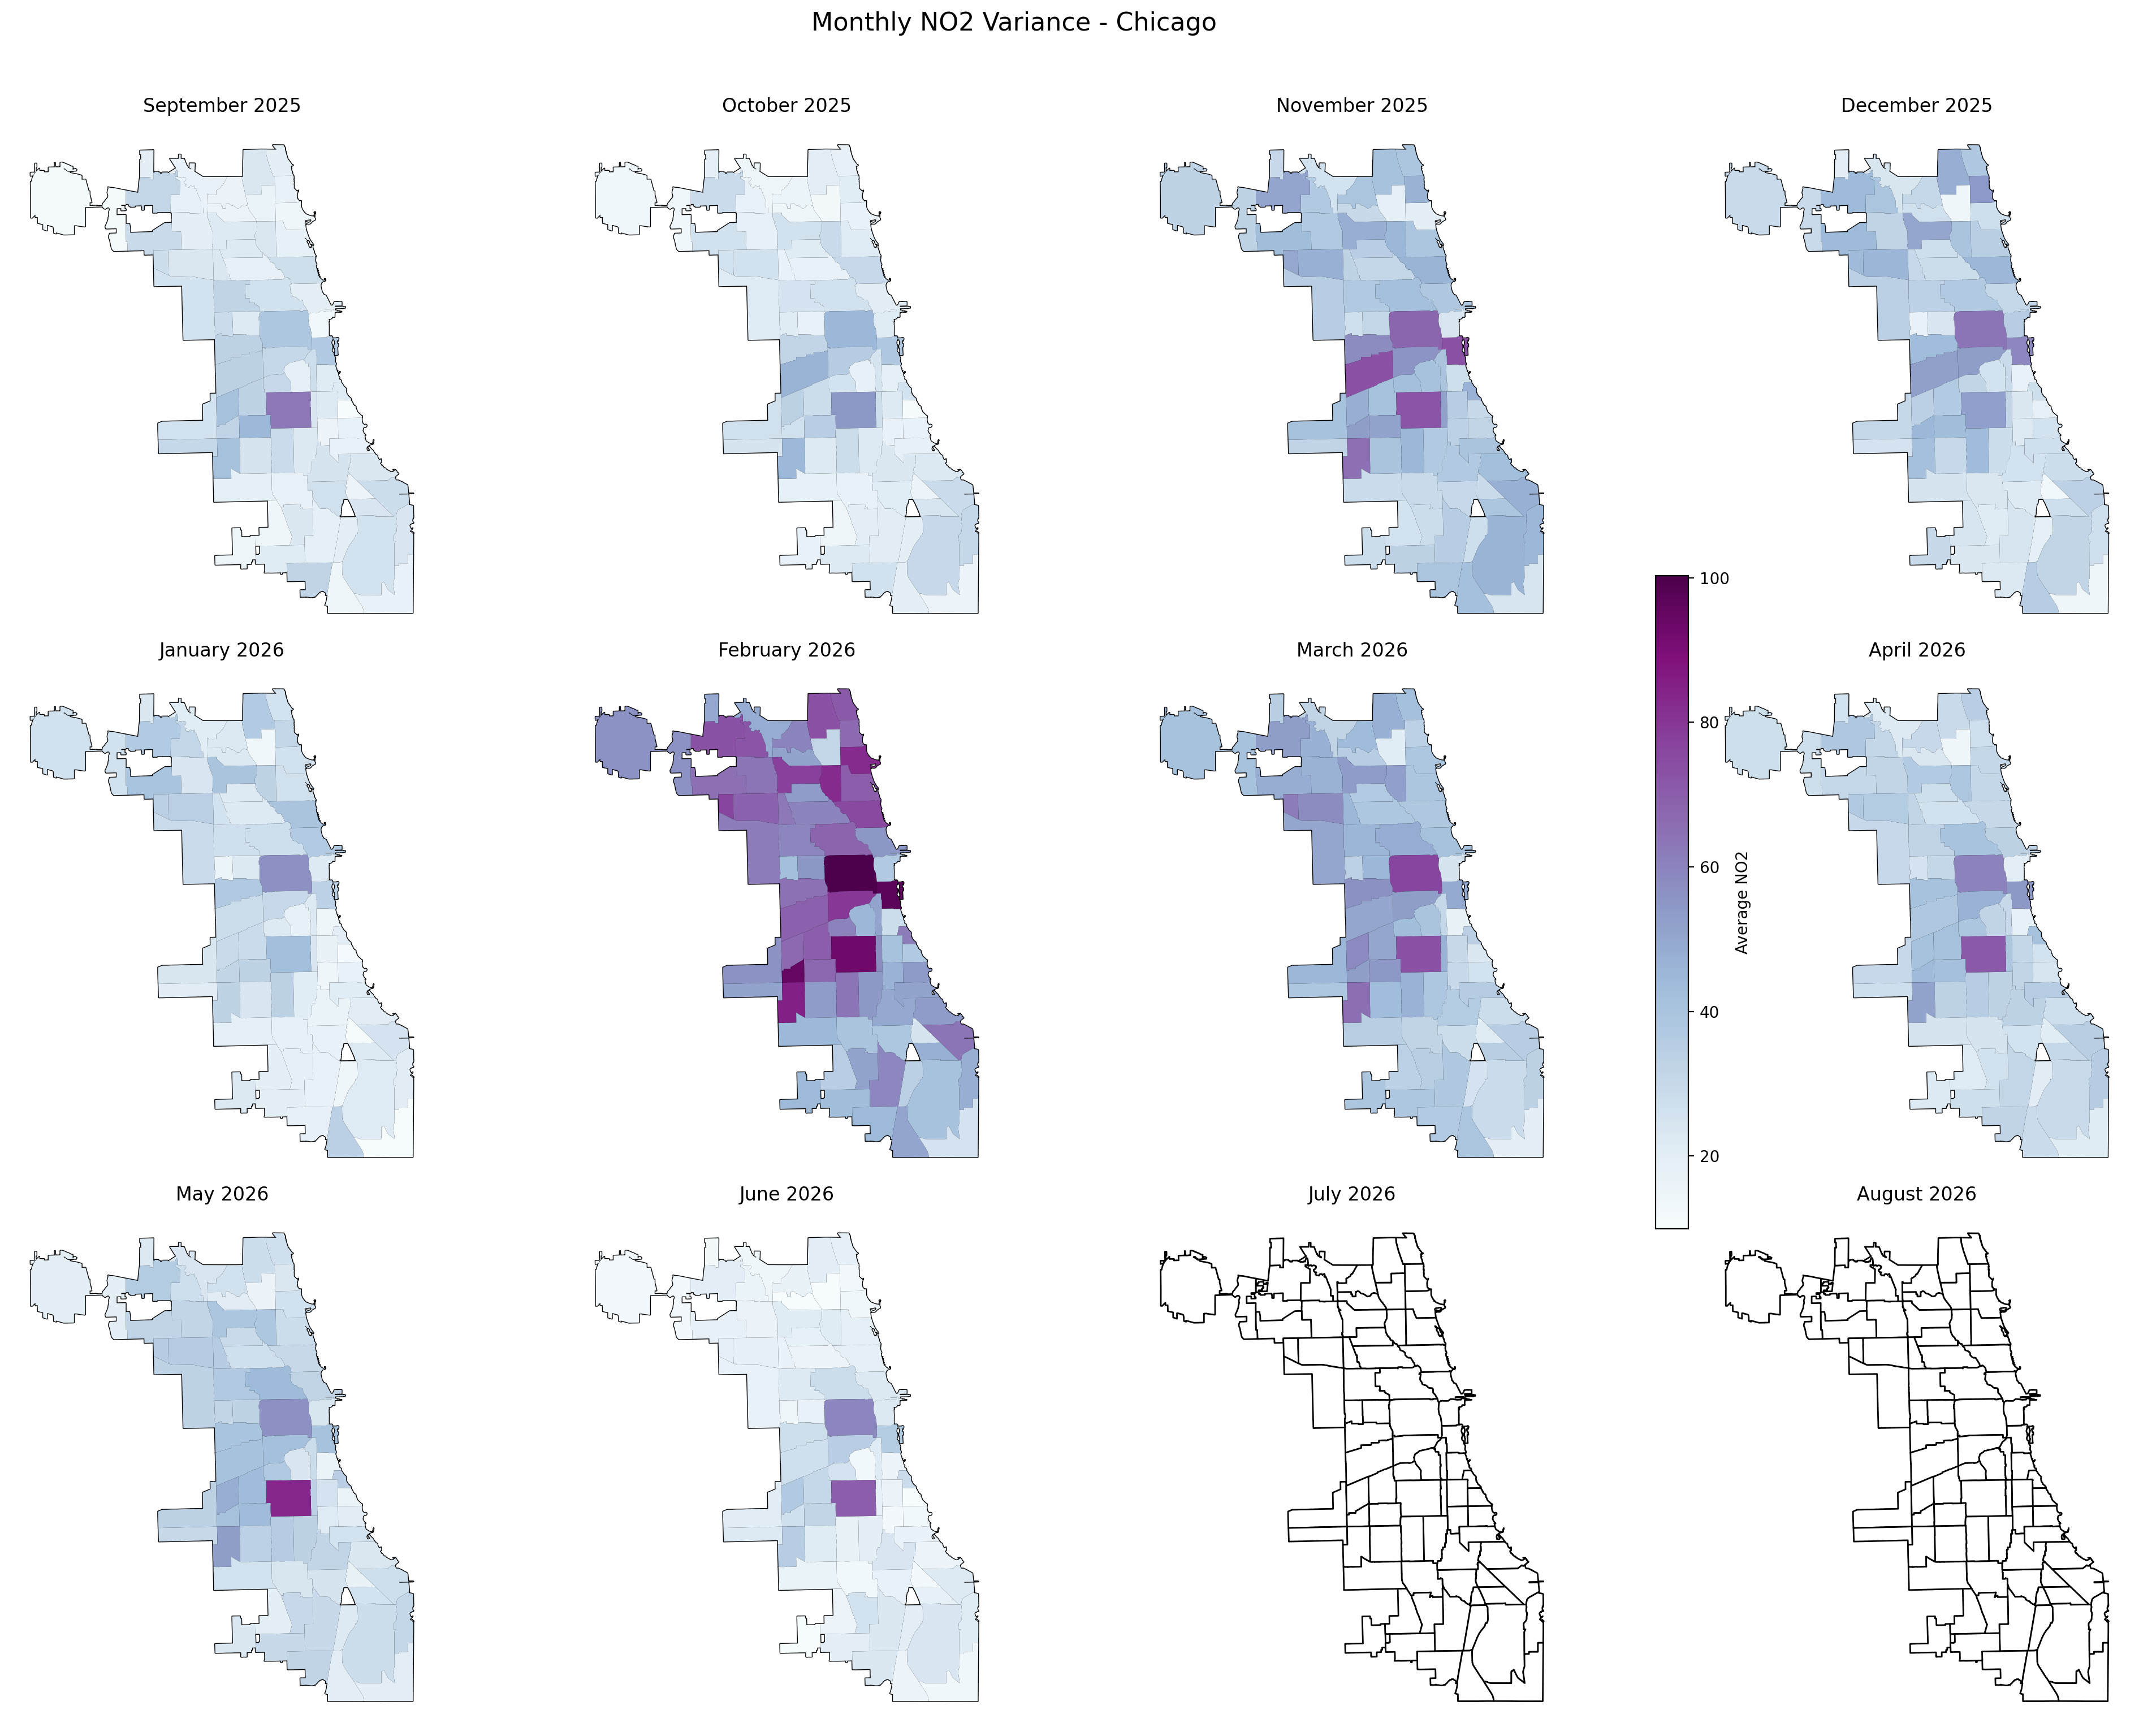

In [83]:

months = chi_result_monthly['month_year'].unique()
months = months[months.argsort()]

start_date = chi_result_monthly['month_year'].min()
end_date = chi_result_monthly['month_year'].max()

delta = relativedelta(months=1)

fig, axes = plt.subplots(
    nrows=3, ncols=4,
    figsize=(20, 15)
)

for ax, month in zip(axes.flatten(), range(1,13)):
    # ax = axes[i]
    
    # Base Chicago boundary
    chicago.plot(color='white', edgecolor='black', ax=ax)
    
    # Filter to month
    monthly_data = chi_result_monthly[chi_result_monthly['month_year'] == start_date]
    
    if not monthly_data.empty:
        monthly_data.plot(ax=ax, column='var_value', cmap='BuPu',
                          vmin=chi_result_monthly['var_value'].min(),
                          vmax=chi_result_monthly['var_value'].max())
    
    # ax.set_title(calendar.month_name[month])
    # ax.axis('off')
  
    title_date = dt.date(start_date.year, start_date.month, start_date.day).strftime('%B %Y')
    ax.set_title(title_date, fontsize=12)
    ax.axis('off')
    start_date += delta

# Shared colorbar
sm = plt.cm.ScalarMappable(
    cmap='BuPu',
    norm=plt.Normalize(
        vmin=chi_result_monthly['var_value'].min(),
        vmax=chi_result_monthly['var_value'].max()
    )
)
sm._A = []
fig.colorbar(sm, ax=axes, shrink=0.5, label='Average NO2')

plt.suptitle('Monthly NO2 Variance - Chicago', fontsize=16, y=1.02)
plt.tight_layout()
plt.savefig("month_var_community.png")
plt.show()

In [49]:
# Calculculate the percent of missing NO2 data per community per month.
chi_summary_na = (
    chi_joined.groupby(["community", "NID", "month", "month_year"])["no2ConcIndividual.value"]
    .apply(lambda x: x.isna().mean())
    .reset_index()
)

# Left joint with spatial dataset 
chi_result_na = chicago.merge(chi_summary_na, on="NID", how="left")

chi_result_na


,community_x,NID,POP2010,POP2000,POPCH,POPPERCH,popplus,popneg,geometry,community_y,month,month_year,no2ConcIndividual.value
0,DOUGLAS,35,18238,26470,-8232,-31.099358,0,1,"MULTIPOLYGON (((-87.60914 41.84469, -87.60915 ...",DOUGLAS,1.0,2026-01-01,0.699203
1,DOUGLAS,35,18238,26470,-8232,-31.099358,0,1,"MULTIPOLYGON (((-87.60914 41.84469, -87.60915 ...",DOUGLAS,2.0,2026-02-01,0.499677
2,DOUGLAS,35,18238,26470,-8232,-31.099358,0,1,"MULTIPOLYGON (((-87.60914 41.84469, -87.60915 ...",DOUGLAS,3.0,2026-03-01,0.137148
3,DOUGLAS,35,18238,26470,-8232,-31.099358,0,1,"MULTIPOLYGON (((-87.60914 41.84469, -87.60915 ...",DOUGLAS,4.0,2026-04-01,0.010604
4,DOUGLAS,35,18238,26470,-8232,-31.099358,0,1,"MULTIPOLYGON (((-87.60914 41.84469, -87.60915 ...",DOUGLAS,5.0,2026-05-01,0.015557
...,...,...,...,...,...,...,...,...,...,...,...,...,...
756,EDISON PARK,9,11187,11259,-72,-0.639488,0,1,"MULTIPOLYGON (((-87.80676 42.00084, -87.80676 ...",EDISON PARK,6.0,2026-06-01,0.000140
757,EDISON PARK,9,11187,11259,-72,-0.639488,0,1,"MULTIPOLYGON (((-87.80676 42.00084, -87.80676 ...",EDISON PARK,9.0,2025-09-01,0.001207
758,EDISON PARK,9,11187,11259,-72,-0.639488,0,1,"MULTIPOLYGON (((-87.80676 42.00084, -87.80676 ...",EDISON PARK,10.0,2025-10-01,0.000195
759,EDISON PARK,9,11187,11259,-72,-0.639488,0,1,"MULTIPOLYGON (((-87.80676 42.00084, -87.80676 ...",EDISON PARK,11.0,2025-11-01,0.146258


/tmp/ipykernel_142334/3430810042.py:48: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


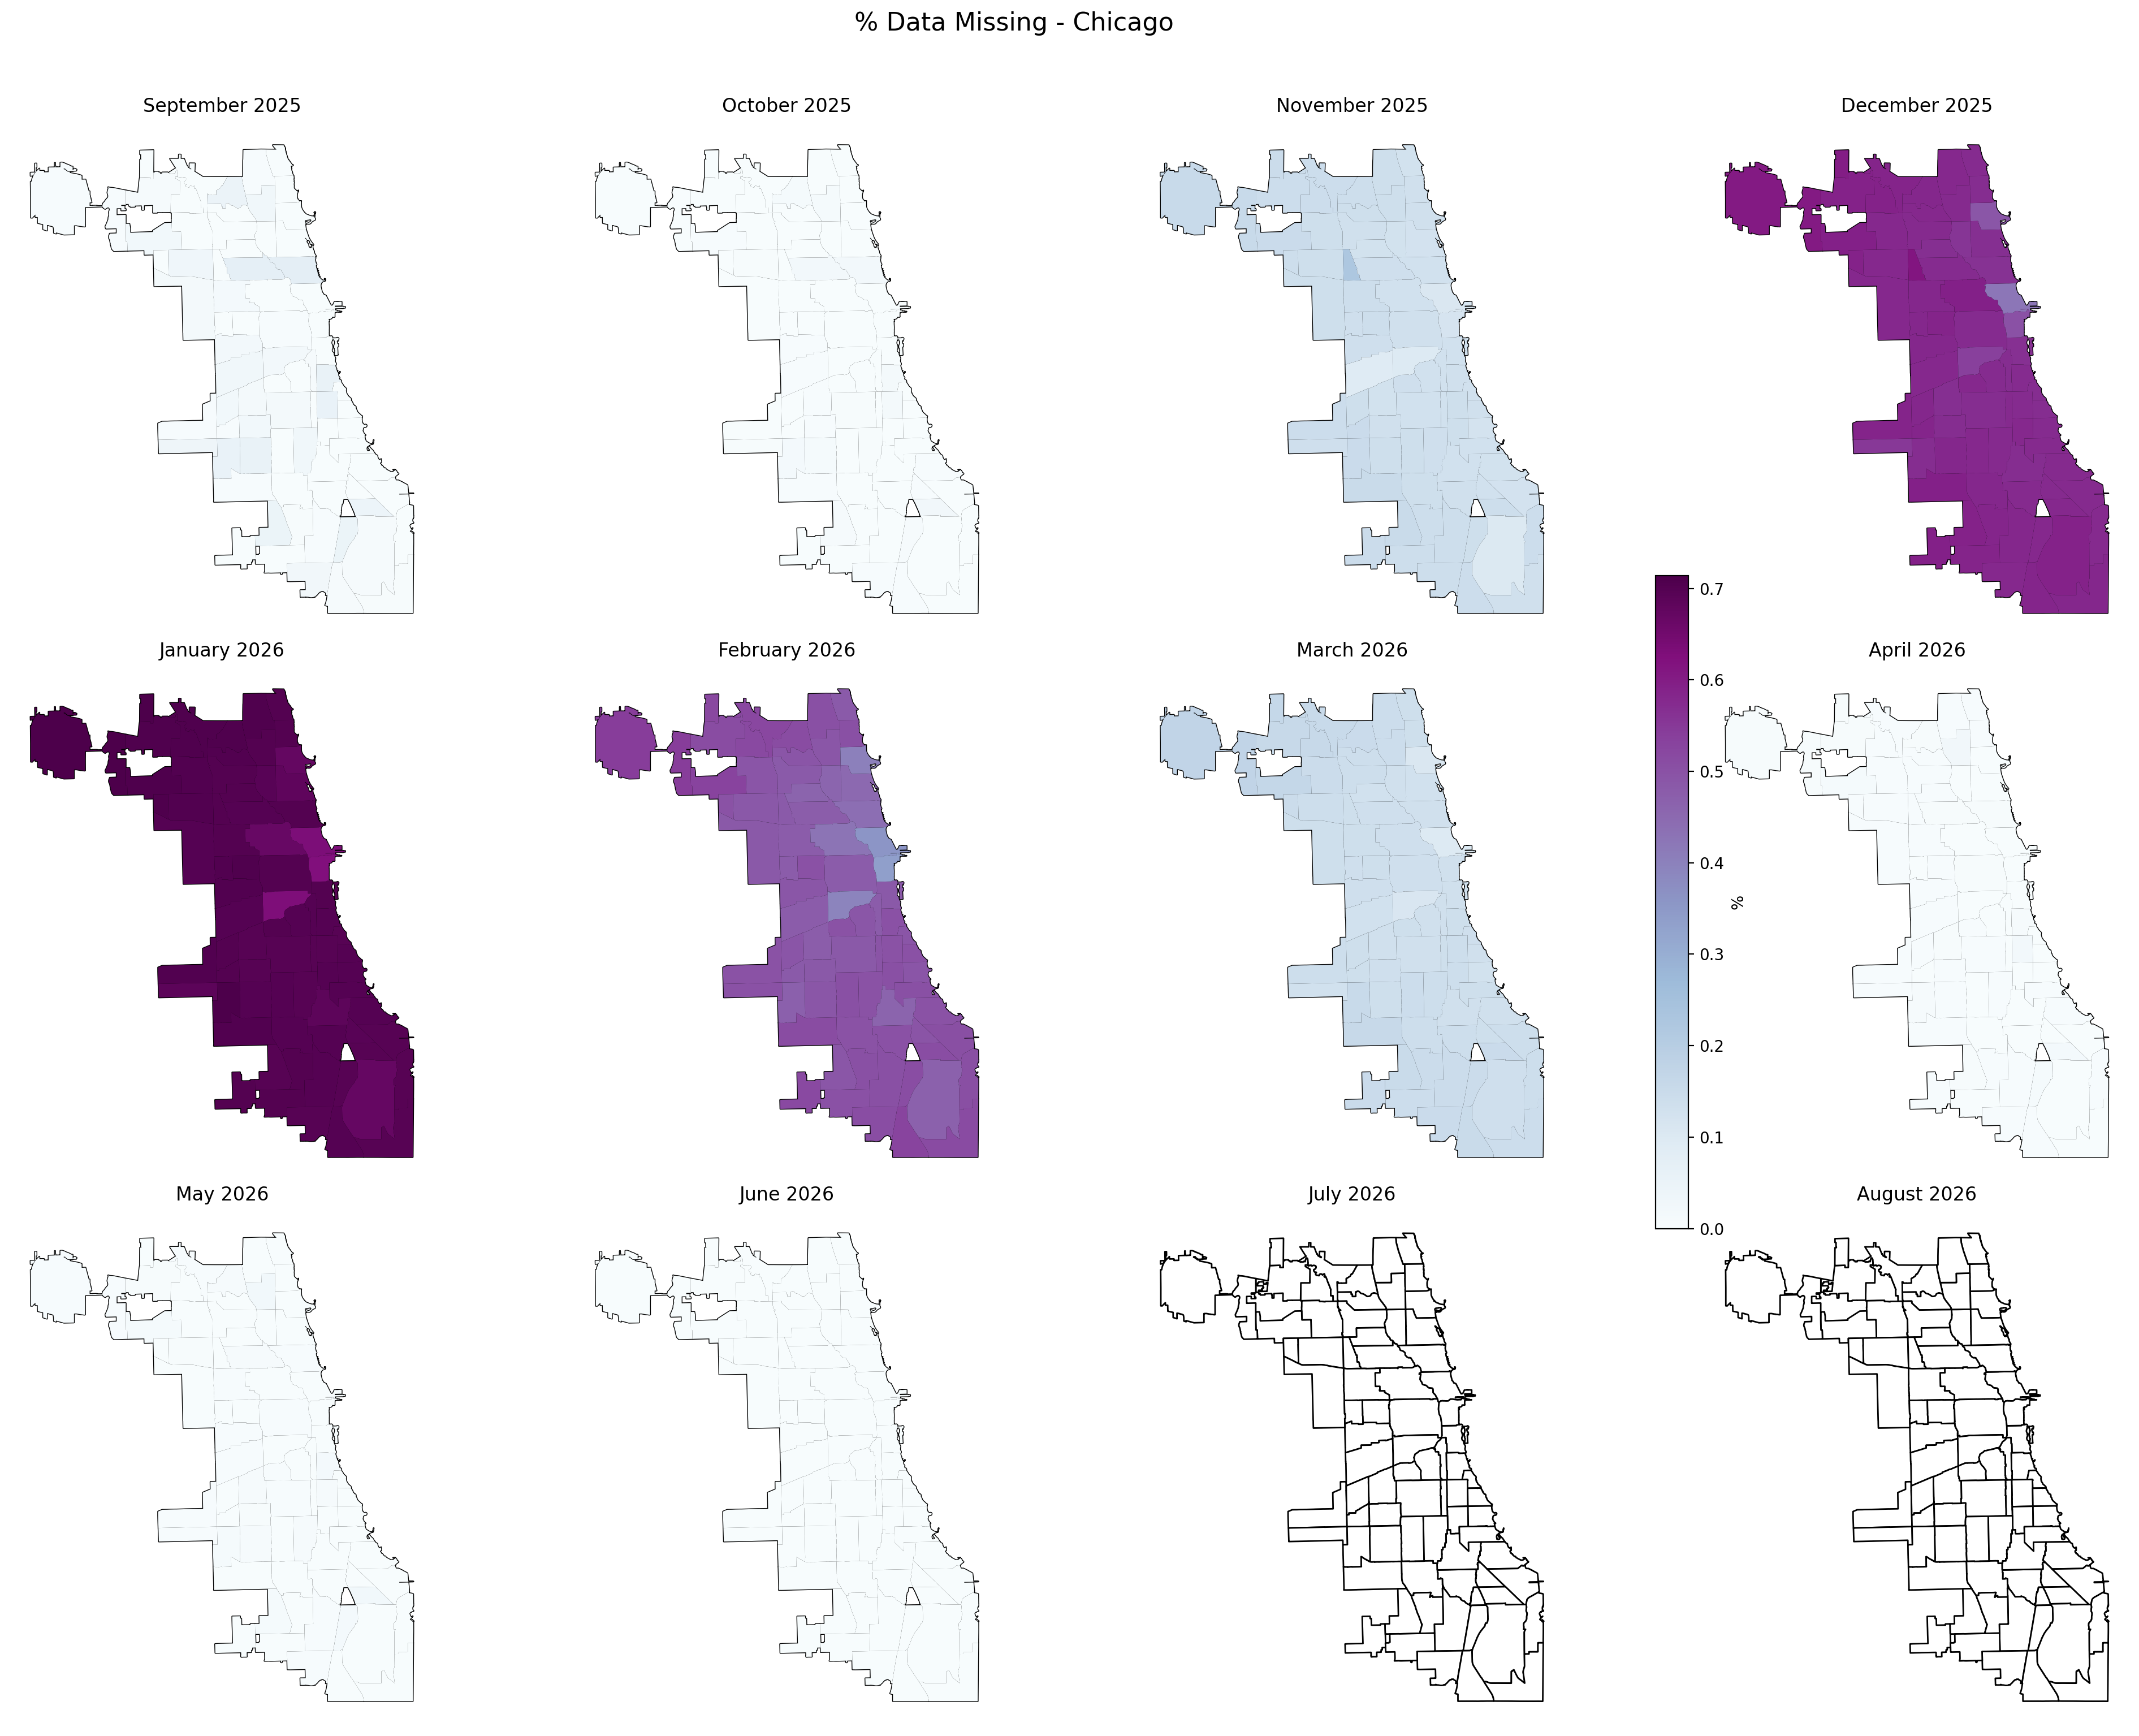

In [ ]:


cook_clarity_na_count = 

months = chi_result_na['month_year'].unique()
months = months[months.argsort()]

start_date = chi_result_na['month_year'].min()
end_date = chi_result_na['month_year'].max()

delta = relativedelta(months=1)

fig, axes = plt.subplots(
    nrows=3, ncols=4,
    figsize=(20, 15)
)

for ax, month in zip(axes.flatten(), range(1,13)):
    # ax = axes[i]
    
    # Base Chicago boundary
    chicago.plot(color='white', edgecolor='black', ax=ax)
    
    # Filter to month
    monthly_data = chi_result_na[chi_result_na['month_year'] == start_date]
    
    if not monthly_data.empty:
        monthly_data.plot(ax=ax, column='no2ConcIndividual.value', cmap='BuPu',
                          vmin=chi_result_na['no2ConcIndividual.value'].min(),
                          vmax=chi_result_na['no2ConcIndividual.value'].max())
    
    # ax.set_title(calendar.month_name[month])
    # ax.axis('off')
  
    title_date = dt.date(start_date.year, start_date.month, start_date.day).strftime('%B %Y')
    ax.set_title(title_date, fontsize=12)
    ax.axis('off')
    start_date += delta

# Shared colorbar
sm = plt.cm.ScalarMappable(
    cmap='BuPu',
    norm=plt.Normalize(
        vmin=chi_result_na['no2ConcIndividual.value'].min(),
        vmax=chi_result_na['no2ConcIndividual.value'].max()
    )
)
sm._A = []
fig.colorbar(sm, ax=axes, shrink=0.5, label='%')

plt.suptitle('% Data Missing - Chicago', fontsize=16, y=1.02)
plt.tight_layout()
# plt.savefig("month_percent_missing-individual.png")
plt.show()

In [7]:
#get % of missing per sensor
#note that this is just for the "no2ConcIndividual.value" variable in the dataframe
cook_clarity_na_count = cook_clarity.groupby(["longitude","latitude","month"])['no2ConcIndividual.value'].apply(lambda x: 100*x.isna().mean()).reset_index()

#Rename column
cook_clarity_na_count.rename(columns={"no2ConcIndividual.value": "num_missing_no2"}, inplace=True)

#Print first five rows
print(cook_clarity_na_count.head())

#Convert above dataframe to geopandas dataframe
#important to assign longitude and latitude for plotting
#This will need to be done for other statistics we calculate per station as well.
cook_clarity_na_count["geometry"] = gpd.points_from_xy(
    x=cook_clarity_na_count["longitude"],
    y=cook_clarity_na_count["latitude"]
)

#Set coordinate reference system to match crs of data we downloaded earlier
cook_clarity_na_count = gpd.GeoDataFrame(cook_clarity_na_count).set_crs(chicago.crs)
# Calculculate the percent of missing NO2 data per community per month.



   longitude   latitude  month  num_missing_no2
0 -87.876252  41.965175      1        71.437917
1 -87.876252  41.965175      2        54.093144
2 -87.876252  41.965175      3        18.643846
3 -87.876252  41.965175      4         3.165836
4 -87.876252  41.965175      5         2.340016


In [ ]:

months = chi_result_na['month_year'].unique()
months = months[months.argsort()]

start_date = chi_result_na['month_year'].min()
end_date = chi_result_na['month_year'].max()

delta = relativedelta(months=1)

fig, axes = plt.subplots(
    nrows=3, ncols=4,
    figsize=(20, 15)
)

for ax, month in zip(axes.flatten(), range(1,13)):
    # ax = axes[i]
    
    # Base Chicago boundary
    chicago.plot(color='white', edgecolor='black', ax=ax)
    
    # Filter to month
    monthly_data = chi_result_na[chi_result_na['month_year'] == start_date]
    
    if not monthly_data.empty:
        monthly_data.plot(ax=ax, column='no2ConcIndividual.value', cmap='BuPu',
                          vmin=chi_result_na['no2ConcIndividual.value'].min(),
                          vmax=chi_result_na['no2ConcIndividual.value'].max())
    
    # ax.set_title(calendar.month_name[month])
    # ax.axis('off')
  
    title_date = dt.date(start_date.year, start_date.month, start_date.day).strftime('%B %Y')
    ax.set_title(title_date, fontsize=12)
    ax.axis('off')
    start_date += delta

# Shared colorbar
sm = plt.cm.ScalarMappable(
    cmap='BuPu',
    norm=plt.Normalize(
        vmin=chi_result_na['no2ConcIndividual.value'].min(),
        vmax=chi_result_na['no2ConcIndividual.value'].max()
    )
)
sm._A = []
fig.colorbar(sm, ax=axes, shrink=0.5, label='%')

plt.suptitle('% Data Missing - Chicago', fontsize=16, y=1.02)
plt.tight_layout()
plt.savefig("month_percent_missing.png")
plt.show()

In [19]:

#get % of missing per sensor
#note that this is just for the "no2ConcIndividual.value" variable in the dataframe
# cook_clarity_na_count_month = (
#     cook_clarity.groupby(["sensor_name", "longitude", "latitude", "month"])["no2ConcIndividual.value"]
#     .apply(lambda x: 100 * x.isna().mean())
#     .reset_index()
# )

cook_clarity_na_count_month = (
    cook_clarity.groupby(["sensor_name", "longitude", "latitude","month"])["no2ConcIndividual.value"]
    .count()
    .reset_index(name="num_vals")
)

#Print first five rows
print(cook_clarity_na_count_month.head())

#Convert above dataframe to geopandas dataframe
#important to assign longitude and latitude for plotting
#This will need to be done for other statistics we calculate per station as well.
cook_clarity_na_count_month["geometry"] = gpd.points_from_xy(
    x=cook_clarity_na_count_month["longitude"],
    y=cook_clarity_na_count_month["latitude"]
)

#Set coordinate reference system to match crs of data we downloaded earlier
cook_clarity_na_count_month = gpd.GeoDataFrame(cook_clarity_na_count_month).set_crs(chicago.crs)

cook_clarity_na_count_month.to_csv("na_count_month.csv")

     sensor_name  longitude   latitude  month  num_vals
0  Albany Park 1 -87.725577  41.975287      1       755
1  Albany Park 1 -87.725577  41.975287      2      1145
2  Albany Park 1 -87.725577  41.975287      3      2176
3  Albany Park 1 -87.725577  41.975287      4      2468
4  Albany Park 1 -87.725577  41.975287      5      4691
